In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned dataset
df = pd.read_csv("../data/processed/customers_clean.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [2]:
print(df[["Contract", "MonthlyCharges", "tenure", "Churn"]].head())

print(df["Churn"].value_counts())
print(df["Contract"].value_counts())

         Contract  MonthlyCharges  tenure Churn
0  Month-to-month           29.85       1    No
1        One year           56.95      34    No
2  Month-to-month           53.85       2   Yes
3        One year           42.30      45    No
4  Month-to-month           70.70       2   Yes
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


In [3]:
contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


In [4]:
import matplotlib.pyplot as plt

In [6]:
from pathlib import Path

# Create the charts folder if it doesn't exist
charts_dir = Path("../charts")
charts_dir.mkdir(parents=True, exist_ok=True)

# Save the chart
plt.savefig(charts_dir / "churn_by_contract.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>

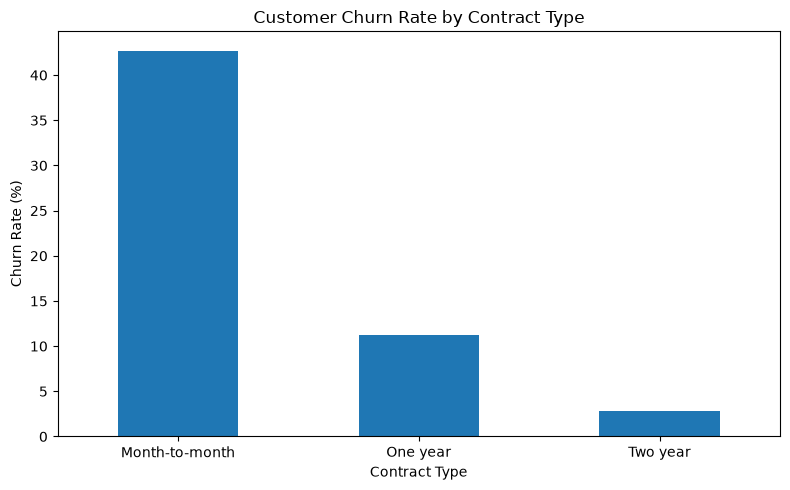

In [7]:
plt.figure(figsize=(8, 5))

contract_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../charts/churn_by_contract.png", dpi=300)
plt.show()

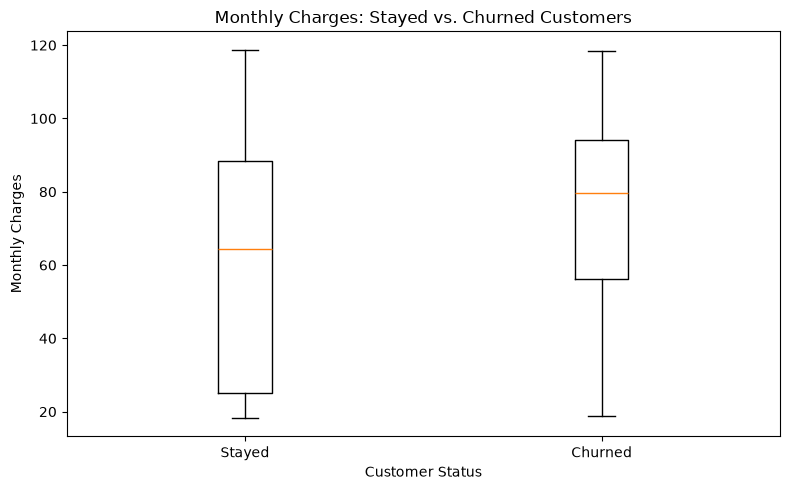

In [ ]:
charge_groups = [
    df.loc[df["Churn"] == "No", "MonthlyCharges"].dropna(),
    df.loc[df["Churn"] == "Yes", "MonthlyCharges"].dropna()
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    charge_groups,
    tick_labels=["Stayed", "Churned"]
)

plt.title("Monthly Charges: Stayed vs. Churned Customers")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()

plt.savefig("../charts/monthly_charges_vs_churn.png", dpi=300)
plt.show()

In [ ]:
bins = [0, 12, 24, 48, 72]
labels = ["0–12 months", "13–24 months",
          "25–48 months", "49–72 months"]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

print(tenure_churn)

TenureGroup
0–12 months     47.438243
13–24 months    28.710938
25–48 months    20.388959
49–72 months     9.513176
Name: Churn, dtype: float64


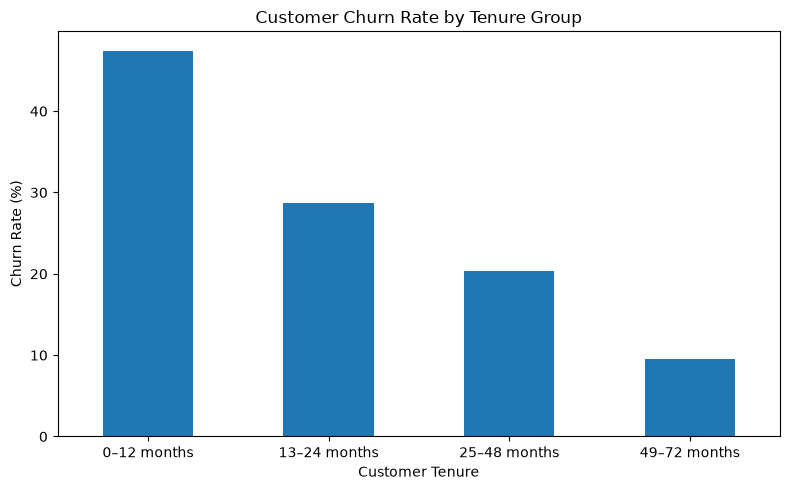

In [ ]:
plt.figure(figsize=(8, 5))

tenure_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../charts/churn_by_tenure.png", dpi=300)
plt.show()

## Business Findings

1. Contract Type:
   The highest churn rate was observed in ______.
   This may indicate an opportunity to investigate retention
   strategies for customers in this group.

2. Monthly Charges:
   Customers who churned had a ______ median monthly charge
   compared with customers who stayed.

3. Customer Tenure:
   The highest churn rate occurred in the ______ tenure group.
   This suggests that the timing of retention efforts may matter.

## Limitations
These findings show associations, not proof of causation.
Further analysis is required to understand the reasons for churn.